# Oxford-IIIT Pet · 02-1: Unsicherheit mit probly

Die [VGG-Baseline](dan_02-0_oxford-pets-vgg16.ipynb) liefert den eingefrorenen Backbone,
die 4.096 Bildmerkmale, den trainierten Kopf und die festen Splits. Wir verwenden diese
Artefakte weiter und untersuchen jetzt:

- **Methoden:** Was ändern MC Dropout und drei unabhängig trainierte Köpfe?
- **Nutzen:** Erkennen Unsicherheitswerte Fehler und helfen sie beim Zurückstellen von Bildern?
- **Belastung:** Wie reagieren Vorhersage und Unsicherheit auf Unschärfe, Rauschen und Verdeckung?
- **Datenmenge:** Wie verändert sich ein Kopfensemble bei 5, 20 oder allen Trainingsbildern je Rasse?

Dieses Notebook verwendet probly für Repräsentationen, Unsicherheitszerlegung, Metriken
und selektive Vorhersage. Regionale Erklärungen folgen in
[02-2 mit shapiq](dan_02-2_oxford-pets-shapiq.ipynb) und
[02-3 mit beiden Bibliotheken](dan_02-3_oxford-pets-combination.ipynb).

In [1]:
from __future__ import annotations

import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter, NullLocator
import numpy as np
import torch
from IPython.display import Markdown, display
from torch import nn
from torchvision.transforms import functional as TF
from torchvision.transforms import v2

notebook_dir = next(
    path / "experiments" / "group-d_experiments"
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "probly").is_dir() and (path / "pyproject.toml").exists()
)
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))

from dan_02_common import (
    ARTIFACT_DIR, REPO_ROOT, DATA_ROOT, load_baseline, make_head, train_head,
    head_logits, load_backbone, load_crop, rgb_tensor, extract_crops,
    load_selection, diagnostic_cases, save_torch, load_torch,
    state_fingerprint, versions,
)
from probly.method import cast, dropout, ensemble
from probly.representer import representer
from probly.quantification import quantify
from probly.metrics import (
    accuracy, log_loss, brier_loss, expected_calibration_error,
    zero_one_loss_per_instance, roc_auc_score,
)
from probly.evaluation.selective_prediction import selective_prediction

torch.set_num_threads(4)
SEED = 0
MODEL_SEEDS = [0, 1, 2]
SUBSET_SEEDS = [10, 11, 12]
MC_SAMPLES = 50
PREDICTION_BATCH_SIZE = 256
N_BINS = 50
PROBLY_DIR = ARTIFACT_DIR / "probly"
PROBLY_DIR.mkdir(parents=True, exist_ok=True)
METHODS = ("baseline", "mc_dropout", "ensemble")
METHOD_NAMES = {"baseline": "Baseline", "mc_dropout": "MC Dropout (50)", "ensemble": "Ensemble (3 Köpfe)"}
METHOD_COLORS = {"baseline": "0.45", "mc_dropout": "tab:blue", "ensemble": "tab:purple"}
NOTION_NAMES = {"total": "TU", "aleatoric": "AU", "epistemic": "EU"}

bundle = load_baseline()
checkpoint = bundle["checkpoint"]
config = dict(checkpoint["config"])
class_names = list(checkpoint["classes"])
baseline_fingerprint = state_fingerprint(checkpoint["head_state_dict"])
trainval = bundle["trainval"]
test = bundle["test"]
train_indices = torch.as_tensor(bundle["train_indices"], dtype=torch.long)
val_indices = torch.as_tensor(bundle["val_indices"], dtype=torch.long)
test_ids = list(test["manifest"]["image_ids"])
selection = load_selection()
assert len(selection["explanation_indices"]) == len(class_names) == 37
assert len(selection["corruption_indices"]) == 370
assert set(train_indices.tolist()).isdisjoint(val_indices.tolist())

print("Versionen:", versions())
print("Trainings-/Validierungs-/Testbilder:", len(train_indices), len(val_indices), len(test["labels"]))
print("VGG-Merkmale:", tuple(trainval["features"].shape))
print("Neue Köpfe und Unsicherheitsberechnung: CPU; neue Bildmerkmale: verfügbares GPU-Gerät.")

Versionen: {'torch': '2.10.0', 'torchvision': '0.25.0', 'numpy': '2.5.3', 'Pillow': '12.2.0', 'probly': '0.1.dev661+g6508e3195', 'shapiq': '1.8.0', 'scikit-learn': '1.8.0'}
Trainings-/Validierungs-/Testbilder: 2944 736 3669
VGG-Merkmale: (3680, 4096)
Neue Köpfe und Unsicherheitsberechnung: CPU; neue Bildmerkmale: verfügbares GPU-Gerät.


## 1. Vergleichbare Modelle mit demselben Vorwissen

Alle Modelle sehen denselben eingefrorenen VGG-Merkmalsraum und verwenden
Dropout(0,5) → Linear(4096,37). Der **Baseline-Kopf wird unverändert übernommen**.
Für das Ensemble trainieren wir zwei weitere Köpfe mit Seeds 1 und 2; Seed 0 ist die
bereits trainierte Baseline. Jeder Kopf erhält denselben Validierungssplit und wählt
seinen eigenen kleinsten Validierungsverlust.

Bei MC Dropout aktiviert probly ausschließlich das schon trainierte Dropout im
**kleinen Kopf**. Der VGG-Backbone bleibt deterministisch. Die Transformation überspringt
hier die einzige, erste parametrisierte Linear-Schicht; wir prüfen, dass keine zweite
Dropout-Schicht und keine veränderten Gewichte entstehen.

Das Kopfensemble entsteht mit probly.ensemble. VGG wird bei Bildern einmal ausgeführt,
danach arbeiten alle Köpfe auf denselben Merkmalen. Ein solches Ensemble erfasst
Unterschiede der Köpfe; Unsicherheit im eingefrorenen VGG selbst erfasst es nicht.

In [2]:
def subset_indices(per_breed: int, subset_seed: int) -> torch.Tensor:
    """Return a nested, stratified subset of the original training indices."""
    generator = torch.Generator().manual_seed(subset_seed)
    selected = []
    for breed in range(len(class_names)):
        candidates = train_indices[trainval["labels"][train_indices] == breed]
        assert len(candidates) >= per_breed
        order = torch.randperm(len(candidates), generator=generator)
        selected.append(candidates[order[:per_breed]])
    return torch.cat(selected).sort().values


expected_subsets = {
    f"k{count}_s{seed}": subset_indices(count, seed)
    for count in (5, 20)
    for seed in SUBSET_SEEDS
}
for seed in SUBSET_SEEDS:
    assert set(expected_subsets[f"k5_s{seed}"].tolist()).issubset(
        expected_subsets[f"k20_s{seed}"].tolist()
    )

model_header = {
    "schema_version": 1,
    "baseline_fingerprint": baseline_fingerprint,
    "classes": class_names,
    "config": config,
    "model_seeds": MODEL_SEEDS,
    "versions": versions(),
    "train_image_ids": [trainval["manifest"]["image_ids"][i] for i in train_indices.tolist()],
    "validation_image_ids": [trainval["manifest"]["image_ids"][i] for i in val_indices.tolist()],
}


def validate_record(record: dict, indices: torch.Tensor) -> None:
    """Check the cached head ensemble and its training identities."""
    assert torch.equal(record["train_indices"], indices)
    assert record["model_seeds"] == MODEL_SEEDS
    assert len(record["states"]) == len(record["histories"]) == len(record["best_epochs"]) == 3
    for state in record["states"]:
        assert all(torch.isfinite(value).all() for value in state.values())
        probe = make_head(config, n_classes=len(class_names), state_dict=state, device="cpu")
        assert sum(isinstance(layer, nn.Dropout) for layer in probe.modules()) == 1


def train_record(indices: torch.Tensor, per_breed, subset_seed=None, reuse_baseline=False) -> dict:
    """Fit three ordinary heads and retain each best validation state."""
    states, histories, best_epochs = [], [], []
    for seed in MODEL_SEEDS:
        if reuse_baseline and seed == 0:
            states.append({key: value.detach().cpu().clone() for key, value in checkpoint["head_state_dict"].items()})
            history_path = ARTIFACT_DIR / "training_history.json"
            histories.append(json.loads(history_path.read_text()) if history_path.exists() else [])
            best_epochs.append(int(checkpoint["best_epoch"]))
            print("Vollständige Trainingsdaten · Kopf 0: Baseline-Checkpoint wiederverwendet.")
            continue
        label = f"alle" if per_breed == "all" else f"{per_breed}/Rasse, Teilmengenseed {subset_seed}"
        print(f"{label} · Kopfseed {seed}")
        head = make_head(config, n_classes=len(class_names), seed=seed, device="cpu")
        fitted = train_head(
            head,
            trainval["features"][indices], trainval["labels"][indices],
            trainval["features"][val_indices], trainval["labels"][val_indices],
            config, seed=seed, device="cpu", verbose=False,
        )
        states.append(fitted["state_dict"])
        histories.append(fitted["history"])
        best_epochs.append(int(fitted["best_epoch"]))
        print(f"  Gewählte Epoche {fitted['best_epoch']}; Val-Loss {fitted['best_val_loss']:.4f}.")
    return {
        "states": states, "histories": histories,
        "train_indices": indices.clone(), "model_seeds": MODEL_SEEDS,
        "per_breed": per_breed, "subset_seed": subset_seed, "best_epochs": best_epochs,
    }


models_path = PROBLY_DIR / "models.pt"
models = None
if models_path.exists():
    candidate = load_torch(models_path)
    try:
        assert all(candidate[key] == value for key, value in model_header.items())
        validate_record(candidate["full"], train_indices)
        assert state_fingerprint(candidate["full"]["states"][0]) == baseline_fingerprint
        assert set(candidate["scarce"]) == set(expected_subsets)
        for key, indices in expected_subsets.items():
            validate_record(candidate["scarce"][key], indices)
        models = candidate
        print("Passende Kopfensembles aus models.pt geladen.")
    except (AssertionError, KeyError, TypeError, ValueError) as error:
        print("Modellcache passt nicht zur aktuellen Konfiguration; erneutes Kopftraining.", type(error).__name__)

if models is None:
    start = time.perf_counter()
    full = train_record(train_indices, "all", reuse_baseline=True)
    scarce = {
        key: train_record(indices, int(key.split("_")[0][1:]), int(key.split("_")[1][1:]))
        for key, indices in expected_subsets.items()
    }
    models = {**model_header, "full": full, "scarce": scarce}
    validate_record(models["full"], train_indices)
    for key, indices in expected_subsets.items():
        validate_record(models["scarce"][key], indices)
    assert state_fingerprint(models["full"]["states"][0]) == baseline_fingerprint
    save_torch(models_path, models)
    print(f"Kopftraining und Speichern: {time.perf_counter() - start:.1f} s.")
print("Vollständiges Ensemble · gewählte Epochen:", models["full"]["best_epochs"])

Passende Kopfensembles aus models.pt geladen.
Vollständiges Ensemble · gewählte Epochen: [5, 10, 7]


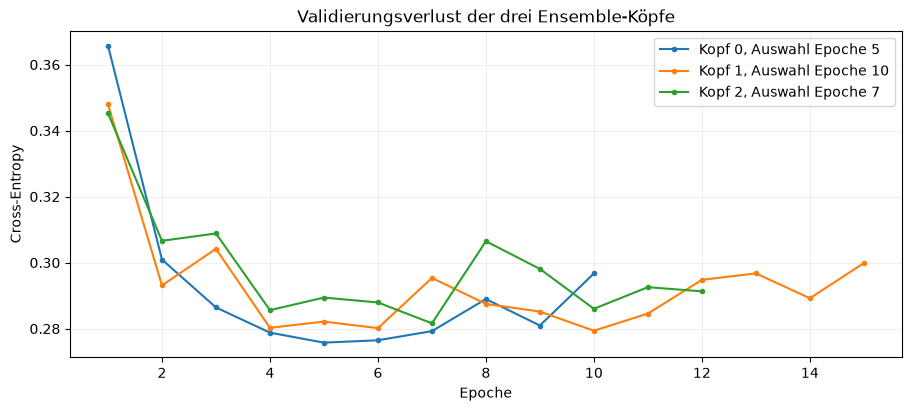

In [3]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for seed, history, best_epoch in zip(
    MODEL_SEEDS, models["full"]["histories"], models["full"]["best_epochs"], strict=True
):
    if history:
        ax.plot(
            [entry["epoch"] for entry in history],
            [entry["val_loss"] for entry in history],
            marker=".", label=f"Kopf {seed}, Auswahl Epoche {best_epoch}",
        )
ax.set(title="Validierungsverlust der drei Ensemble-Köpfe", xlabel="Epoche", ylabel="Cross-Entropy")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

## 2. Repräsentieren, quantifizieren und Fehler erkennen

Für MC Dropout sammelt der Representer 50 Ausgaben; beim Ensemble nimmt er jeden Kopf
genau einmal. Der Mittelwert wird **nach Softmax über die Wahrscheinlichkeiten** gebildet.

Problys Entropiezerlegung liefert Gesamtunsicherheit TU, mittlere Einzelunsicherheit AU
und Uneinigkeit EU. Die Werte sind in nats. Für die deterministische Baseline ist nur TU
definiert; wir erfinden für sie keine aleatorische/epistemische Zerlegung.

Neben Accuracy vergleichen wir NLL, Brier und ECE mit 15 Bins. Error-AUROC prüft, ob
Fehler höhere Werte erhalten als Treffer; 0,5 entspricht zufälliger Trennung.
Ein guter Wert ist nützlich, beweist aber keine korrekte Interpretation einzelner Bilder.

In [4]:
def build_predictor(method: str, record: dict):
    """Build a genuine probly predictor from already selected head states."""
    if method == "ensemble":
        predictor = ensemble(
            make_head(config, n_classes=len(class_names), seed=SEED, device="cpu"),
            num_members=3, reset_params=False, predictor_type="logit_classifier",
        )
        for member, state in zip(predictor, record["states"], strict=True):
            member.load_state_dict(state)
        return predictor.eval()
    head = make_head(
        config, n_classes=len(class_names), state_dict=record["states"][0], device="cpu"
    )
    if method == "mc_dropout":
        expected = state_fingerprint(head.state_dict())
        predictor = dropout(head, p=config["dropout"], predictor_type="logit_classifier").eval()
        assert state_fingerprint(predictor.state_dict()) == expected
        assert sum(isinstance(layer, nn.Dropout) for layer in predictor.modules()) == 1
        return predictor
    return cast(head, predictor_type="logit_classifier").eval()


def score_features(features: torch.Tensor, method: str, record: dict) -> dict:
    """Use probly representations and quantification with reproducible CPU sampling."""
    predictor = build_predictor(method, record)
    rep = representer(predictor, num_samples=MC_SAMPLES) if method == "mc_dropout" else representer(predictor)
    outputs = {"probabilities": [], "total": [], "aleatoric": [], "epistemic": []}
    with torch.random.fork_rng(devices=[]), torch.no_grad():
        torch.random.default_generator.manual_seed(SEED)
        for batch in features.split(PREDICTION_BATCH_SIZE):
            representation = rep.represent(batch)
            distribution = representation if method == "baseline" else representation.sample_mean()
            outputs["probabilities"].append(distribution.probabilities.detach().cpu())
            uq = quantify(representation)
            outputs["total"].append(uq.total.detach().cpu())
            if method != "baseline":
                outputs["aleatoric"].append(uq.aleatoric.detach().cpu())
                outputs["epistemic"].append(uq.epistemic.detach().cpu())
    scores = {
        key: torch.cat(value) if value else None
        for key, value in outputs.items()
    }
    assert scores["probabilities"].shape == (len(features), len(class_names))
    assert all(value is None or torch.isfinite(value).all() for value in scores.values())
    torch.testing.assert_close(
        scores["probabilities"].sum(1), torch.ones(len(features)), rtol=1e-5, atol=1e-6
    )
    if method != "baseline":
        torch.testing.assert_close(
            scores["total"], scores["aleatoric"] + scores["epistemic"], rtol=1e-4, atol=1e-6
        )
    assert not any(layer.training for layer in predictor.modules())
    return scores


def summarize(scores: dict, labels: torch.Tensor) -> dict:
    """Evaluate predictive distributions and error-detection scores with probly."""
    probabilities = scores["probabilities"]
    errors = zero_one_loss_per_instance(probabilities, labels)
    result = {
        "n": len(labels),
        "accuracy": float(accuracy(probabilities, labels)),
        "nll": float(log_loss(probabilities, labels)),
        "brier": float(brier_loss(probabilities, labels)),
        "ece15": float(expected_calibration_error(probabilities, labels, num_bins=15)),
        "errors": int(errors.sum()),
    }
    criteria = {**{name: scores[name] for name in NOTION_NAMES}, "confidence": 1 - probabilities.max(1).values}
    for name, criterion in criteria.items():
        if criterion is None:
            result[f"mean_{name}"] = None
            result[f"error_auroc_{name}"] = None
        else:
            result[f"mean_{name}"] = float(criterion.mean())
            result[f"error_auroc_{name}"] = (
                float(roc_auc_score(errors.long(), criterion))
                if errors.unique().numel() == 2 else None
            )
    return result


prediction_header = {
    "schema_version": 1, "baseline_fingerprint": baseline_fingerprint,
    "classes": class_names, "test_image_ids": test_ids,
    "model_fingerprints": {
        key: [state_fingerprint(state) for state in record["states"]]
        for key, record in {"full": models["full"], **models["scarce"]}.items()
    },
    "mc_samples": MC_SAMPLES, "mc_seed": SEED,
    "batch_size": PREDICTION_BATCH_SIZE, "versions": versions(),
}
predictions_path = PROBLY_DIR / "test_predictions.pt"
prediction_payload = load_torch(predictions_path) if predictions_path.exists() else None
if prediction_payload is None or prediction_payload.get("manifest") != prediction_header:
    records = {method: score_features(test["features"], method, models["full"]) for method in METHODS}
    records.update({
        key: score_features(test["features"], "ensemble", record)
        for key, record in models["scarce"].items()
    })
    for scores in records.values():
        scores["predictions"] = scores["probabilities"].argmax(1)
        scores["errors"] = (scores["predictions"] != test["labels"]).long()
    prediction_payload = {
        "manifest": prediction_header, "labels": test["labels"], "image_ids": test_ids, "records": records,
    }
    save_torch(predictions_path, prediction_payload)
    print("Testvorhersagen mit probly berechnet und gespeichert.")
else:
    print("Passende Testvorhersagen geladen.")
test_scores = prediction_payload["records"]
method_metrics = {method: summarize(test_scores[method], test["labels"]) for method in METHODS}

rows = ["| Methode | Accuracy | NLL | Brier | ECE (15 Bins) | Fehler |",
        "| :--- | ---: | ---: | ---: | ---: | ---: |"]
for method in METHODS:
    row = method_metrics[method]
    rows.append(
        f"| {METHOD_NAMES[method]} | {row['accuracy']:.2%} | {row['nll']:.4f} | "
        f"{row['brier']:.4f} | {row['ece15']:.4f} | {row['errors']} |"
    )
display(Markdown("\n".join(rows)))

auroc_rows = ["| Methode | TU | AU | EU | 1 − höchste Wahrscheinlichkeit |",
              "| :--- | ---: | ---: | ---: | ---: |"]
for method in METHODS:
    values = [method_metrics[method][f"error_auroc_{key}"] for key in (*NOTION_NAMES, "confidence")]
    formatted = ["—" if value is None else f"{value:.3f}" for value in values]
    auroc_rows.append(f"| {METHOD_NAMES[method]} | " + " | ".join(formatted) + " |")
display(Markdown("**Error-AUROC auf dem vollständigen Testsplit**\n\n" + "\n".join(auroc_rows)))

Passende Testvorhersagen geladen.


| Methode | Accuracy | NLL | Brier | ECE (15 Bins) | Fehler |
| :--- | ---: | ---: | ---: | ---: | ---: |
| Baseline | 90.11% | 0.2845 | 0.1404 | 0.0133 | 363 |
| MC Dropout (50) | 90.19% | 0.2837 | 0.1400 | 0.0129 | 360 |
| Ensemble (3 Köpfe) | 89.86% | 0.2825 | 0.1389 | 0.0187 | 372 |

**Error-AUROC auf dem vollständigen Testsplit**

| Methode | TU | AU | EU | 1 − höchste Wahrscheinlichkeit |
| :--- | ---: | ---: | ---: | ---: |
| Baseline | 0.913 | — | — | 0.916 |
| MC Dropout (50) | 0.911 | 0.909 | 0.907 | 0.916 |
| Ensemble (3 Köpfe) | 0.921 | 0.921 | 0.889 | 0.925 |

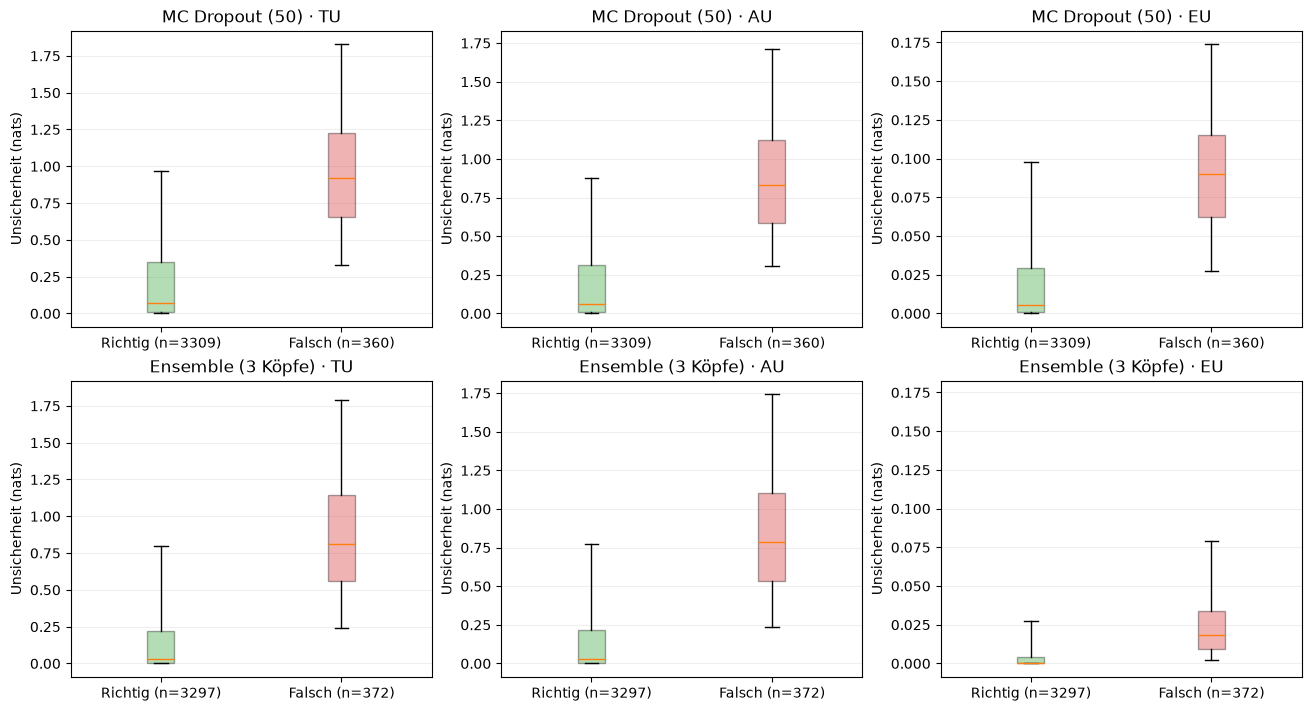

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey="col", layout="constrained")
for row, method in enumerate(("mc_dropout", "ensemble")):
    scores = test_scores[method]
    errors = scores["probabilities"].argmax(1) != test["labels"]
    for column, (notion, short_name) in enumerate(NOTION_NAMES.items()):
        groups = [scores[notion][~errors].numpy(), scores[notion][errors].numpy()]
        artists = axes[row, column].boxplot(
            groups, tick_labels=[f"Richtig (n={len(groups[0])})", f"Falsch (n={len(groups[1])})"],
            whis=(5, 95), showfliers=False, patch_artist=True,
        )
        for patch, color in zip(artists["boxes"], ("tab:green", "tab:red"), strict=True):
            patch.set_facecolor(color)
            patch.set_alpha(0.35)
        axes[row, column].set_title(f"{METHOD_NAMES[method]} · {short_name}")
        axes[row, column].set_ylabel("Unsicherheit (nats)")
        axes[row, column].grid(axis="y", alpha=0.2)
plt.show()

Die Boxen zeigen Median und mittlere 50 %; die Whisker reichen vom 5. bis zum 95. Perzentil.
Überlappende Verteilungen sind zu erwarten: Ein unsicheres Bild muss nicht falsch
klassifiziert werden, und ein Modell kann trotz geringer Uneinigkeit falsch liegen.

## 3. Selektive Vorhersage: Welche Bilder zurückstellen?

Wir sortieren Bilder nach einem Unsicherheitskriterium und stellen die höchsten Werte
zuerst zurück. Die Risk-Coverage-Kurve zeigt die Fehlerrate unter den verbleibenden Bildern.
Die horizontale Linie ist die erwartete Fehlerrate bei zufälliger Zurückstellung.

Probly verwendet 50 Bins mit ganzzahliger Binbreite. Die x-Koordinaten unten sind die
tatsächlich verbleibenden Anteile, nicht eine angenommene gleichmäßige Skala.
Der zurückgegebene Kennwert wird als **probly AURC (50 Bins)** bezeichnet; er ist keine
neu implementierte, exakte Rang-für-Rang-AURC.

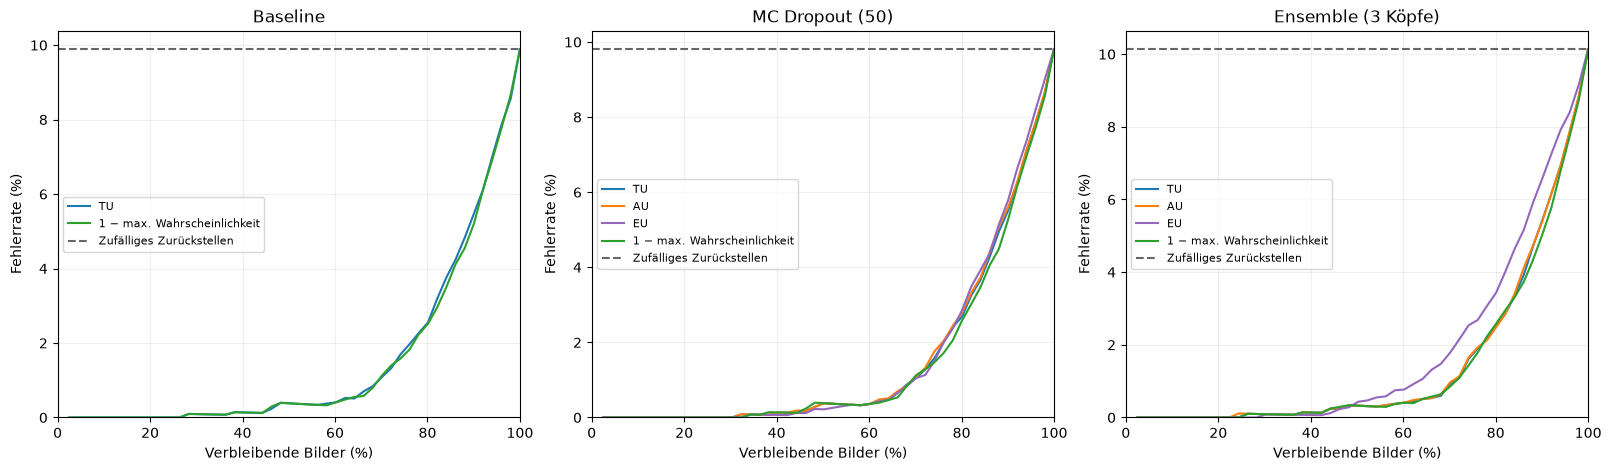

| Methode / Kriterium | probly AURC | Fehler bei ≈80 % | Fehler bei ≈90 % |
| :--- | ---: | ---: | ---: |
| Baseline / TU | 0.0150 | 2.55% (80.1%) | 5.48% (90.1%) |
| Baseline / 1 − max. Wahrscheinlichkeit | 0.0146 | 2.52% (80.1%) | 5.21% (90.1%) |
| MC Dropout (50) / TU | 0.0149 | 2.69% (80.1%) | 5.51% (90.1%) |
| MC Dropout (50) / AU | 0.0152 | 2.79% (80.1%) | 5.60% (90.1%) |
| MC Dropout (50) / EU | 0.0153 | 2.86% (80.1%) | 5.78% (90.1%) |
| MC Dropout (50) / 1 − max. Wahrscheinlichkeit | 0.0144 | 2.59% (80.1%) | 5.27% (90.1%) |
| Ensemble (3 Köpfe) / TU | 0.0145 | 2.52% (80.1%) | 5.42% (90.1%) |
| Ensemble (3 Köpfe) / AU | 0.0147 | 2.48% (80.1%) | 5.39% (90.1%) |
| Ensemble (3 Köpfe) / EU | 0.0182 | 3.44% (80.1%) | 6.57% (90.1%) |
| Ensemble (3 Köpfe) / 1 − max. Wahrscheinlichkeit | 0.0142 | 2.59% (80.1%) | 5.02% (90.1%) |

In [6]:
CRITERION_NAMES = {"total": "TU", "aleatoric": "AU", "epistemic": "EU", "confidence": "1 − max. Wahrscheinlichkeit"}
CRITERION_COLORS = {"total": "tab:blue", "aleatoric": "tab:orange", "epistemic": "tab:purple", "confidence": "tab:green"}
risk_curves, risk_rows = {}, []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
for ax, method in zip(axes, METHODS, strict=True):
    scores = test_scores[method]
    losses = zero_one_loss_per_instance(scores["probabilities"], test["labels"])
    count = len(losses)
    coverage = (count - torch.arange(N_BINS) * (count // N_BINS)).double() / count
    criteria = {**{key: scores[key] for key in NOTION_NAMES}, "confidence": 1 - scores["probabilities"].max(1).values}
    risk_curves[method] = {}
    for name, criterion in criteria.items():
        if criterion is None:
            continue
        aurc, bin_losses = selective_prediction(criterion, losses, n_bins=N_BINS)
        risk_curves[method][name] = {
            "aurc": float(aurc), "coverage": coverage, "risk": bin_losses.cpu(),
        }
        ax.plot(
            100 * coverage.numpy(), 100 * bin_losses.numpy(),
            label=CRITERION_NAMES[name], color=CRITERION_COLORS[name],
        )
        near80 = int(torch.where(coverage >= 0.8)[0][-1])
        near90 = int(torch.where(coverage >= 0.9)[0][-1])
        risk_rows.append({
            "method": method, "criterion": name, "aurc": float(aurc),
            "coverage80": float(coverage[near80]), "risk80": float(bin_losses[near80]),
            "coverage90": float(coverage[near90]), "risk90": float(bin_losses[near90]),
        })
    ax.axhline(float(losses.mean()) * 100, linestyle="--", color="0.4", label="Zufälliges Zurückstellen")
    ax.set(title=METHOD_NAMES[method], xlabel="Verbleibende Bilder (%)", ylabel="Fehlerrate (%)", xlim=(0, 100), ylim=(0, None))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.show()
save_torch(PROBLY_DIR / "risk_coverage.pt", {"manifest": prediction_header, "curves": risk_curves})

table = ["| Methode / Kriterium | probly AURC | Fehler bei ≈80 % | Fehler bei ≈90 % |",
         "| :--- | ---: | ---: | ---: |"]
for row in risk_rows:
    table.append(
        f"| {METHOD_NAMES[row['method']]} / {CRITERION_NAMES[row['criterion']]} | {row['aurc']:.4f} | "
        f"{row['risk80']:.2%} ({row['coverage80']:.1%}) | {row['risk90']:.2%} ({row['coverage90']:.1%}) |"
    )
display(Markdown("\n".join(table)))

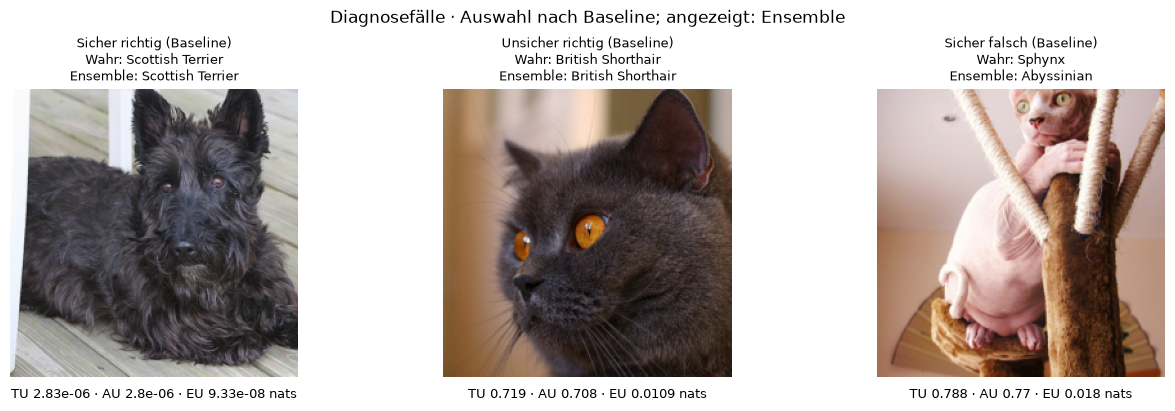

In [7]:
cases = diagnostic_cases(bundle, selection)[:6]
gallery_rows = max(1, (len(cases) + 2) // 3)
fig, axes = plt.subplots(gallery_rows, 3, figsize=(13, 4 * gallery_rows), squeeze=False, layout="constrained")
for ax in axes.flat:
    ax.axis("off")
for ax, case in zip(axes.flat, cases):
    index = int(case["index"])
    scores = test_scores["ensemble"]
    prediction = int(scores["probabilities"][index].argmax())
    ax.imshow(load_crop(case["image_id"]))
    ax.set_title(
        f"{case['role']} (Baseline)\nWahr: {class_names[int(test['labels'][index])]}\n"
        f"Ensemble: {class_names[prediction]}", fontsize=9,
    )
    ax.text(
        0.5, -0.04,
        f"TU {scores['total'][index]:.3g} · AU {scores['aleatoric'][index]:.3g} · EU {scores['epistemic'][index]:.3g} nats",
        transform=ax.transAxes, ha="center", va="top", fontsize=9,
    )
fig.suptitle("Diagnosefälle · Auswahl nach Baseline; angezeigt: Ensemble")
plt.show()

## 4. Kontrollierte Bildveränderungen

Wir verwenden eine feste, geschichtete Stichprobe von **370 Testbildern: zehn je Rasse**.
Jedes Bild wird mit seinem unveränderten Gegenstück verglichen:

- Unschärfe: Gaussian Blur, Sigma 1 / 2 / 4.
- Rauschen: GaussianNoise, RGB-Standardabweichung 0,02 / 0,05 / 0,10, auf [0,1] begrenzt.
- Verdeckung: zentrales Quadrat mit Kantenlänge 32 / 64 / 96 Pixeln, gefüllt mit ImageNet-Mittelwert.

Alle Veränderungen erfolgen auf dem RGB-Ausschnitt vor der Normalisierung.
Rauschen verwendet bei jeder Stärke dieselben zugrunde liegenden Zufallsziehungen.
MC Dropout verwendet innerhalb dieser gepaarten Auswertung ebenfalls dieselbe Maskenfolge
bei gleicher Bildreihenfolge und Batchgröße. Die sauberen MC-Werte dieser Stichprobe werden
dafür neu berechnet; sie müssen nicht exakt den aus der Gesamttestauswertung herausgegriffenen
MC-Schätzungen entsprechen.

Die Testbilder behalten ihre ursprünglichen Rasse-Labels. Dieses Experiment misst Robustheit
unter kontrollierter Veränderung und ist kein Benchmark mit unbekannten Klassen.

In [8]:
corruption_indices = torch.tensor(selection["corruption_indices"], dtype=torch.long)
corruption_ids = list(selection["corruption_ids"])
assert [test_ids[index] for index in corruption_indices.tolist()] == corruption_ids
assert torch.bincount(test["labels"][corruption_indices], minlength=37).tolist() == [10] * 37
corruption_labels = test["labels"][corruption_indices]

CORRUPTION_SPECS = (
    [{"key": f"blur_s{sigma:g}", "family": "blur", "value": sigma} for sigma in (1.0, 2.0, 4.0)]
    + [{"key": f"noise_s{sigma:g}", "family": "noise", "value": sigma} for sigma in (0.02, 0.05, 0.10)]
    + [{"key": f"occlusion_e{edge}", "family": "occlusion", "value": edge} for edge in (32, 64, 96)]
)
rgb_mean = torch.tensor(checkpoint["preprocessing"]["mean"]).view(3, 1, 1)


def corrupt_crop(crop, spec: dict) -> torch.Tensor:
    """Apply a library transform to a cropped, unnormalized RGB image."""
    image = rgb_tensor(crop)
    if spec["family"] == "blur":
        return v2.GaussianBlur(kernel_size=31, sigma=float(spec["value"]))(image)
    if spec["family"] == "noise":
        return v2.GaussianNoise(mean=0.0, sigma=float(spec["value"]), clip=True)(image)
    edge = int(spec["value"])
    start = (image.shape[-1] - edge) // 2
    return TF.erase(image, start, start, edge, edge, v=rgb_mean, inplace=False)


corruption_manifest = {
    **prediction_header, "source_image_ids": corruption_ids,
    "specifications": CORRUPTION_SPECS, "perturbation_seed": SEED,
    "rgb_fill": rgb_mean.flatten().tolist(), "space": "RGB_0_1_after_224_crop_before_normalization",
    "feature_source_manifest": test["manifest"],
}
corruption_scores_path = PROBLY_DIR / "corruption_predictions.pt"
corruption_payload = load_torch(corruption_scores_path) if corruption_scores_path.exists() else None
if corruption_payload is None or corruption_payload.get("manifest") != corruption_manifest:
    corruption_feature_dir = PROBLY_DIR / "corruption_features"
    corruption_feature_dir.mkdir(parents=True, exist_ok=True)
    all_corruption_scores = {
        "clean": {
            method: score_features(test["features"][corruption_indices], method, models["full"])
            for method in METHODS
        }
    }
    backbone = None
    for spec in CORRUPTION_SPECS:
        feature_path = corruption_feature_dir / f"{spec['key']}.pt"
        feature_manifest = {
            "schema_version": 1, "source_image_ids": corruption_ids, "spec": spec,
            "seed": SEED, "rgb_fill": rgb_mean.flatten().tolist(),
            "preprocessing": checkpoint["preprocessing"],
            "weights": checkpoint["weights"], "versions": versions(),
        }
        feature_payload = load_torch(feature_path) if feature_path.exists() else None
        cache_ok = (
            feature_payload is not None
            and feature_payload.get("manifest") == feature_manifest
            and tuple(feature_payload["features"].shape) == (370, config["feature_dim"])
            and bool(torch.isfinite(feature_payload["features"]).all())
        )
        if not cache_ok:
            if backbone is None:
                backbone = load_backbone()
            with torch.random.fork_rng(devices=[]):
                torch.random.default_generator.manual_seed(SEED)
                crops = (corrupt_crop(load_crop(image_id), spec) for image_id in corruption_ids)
                features = extract_crops(backbone, crops, batch_size=4)
            feature_payload = {"manifest": feature_manifest, "features": features}
            save_torch(feature_path, feature_payload)
            print(spec["key"], "· neue VGG-Merkmale gespeichert.")
        else:
            print(spec["key"], "· Merkmalscache geladen.")
        all_corruption_scores[spec["key"]] = {
            method: score_features(feature_payload["features"], method, models["full"])
            for method in METHODS
        }
    for per_method in all_corruption_scores.values():
        for scores in per_method.values():
            scores["predictions"] = scores["probabilities"].argmax(1)
            scores["errors"] = (scores["predictions"] != corruption_labels).long()
    corruption_payload = {
        "manifest": corruption_manifest, "image_ids": corruption_ids,
        "labels": corruption_labels, "records": all_corruption_scores,
    }
    save_torch(corruption_scores_path, corruption_payload)
    del backbone
else:
    print("Passende gepaarte Korruptionsauswertung geladen.")

corruption_scores = corruption_payload["records"]
corruption_metrics = {
    key: {method: summarize(scores, corruption_labels) for method, scores in per_method.items()}
    for key, per_method in corruption_scores.items()
}

Passende gepaarte Korruptionsauswertung geladen.


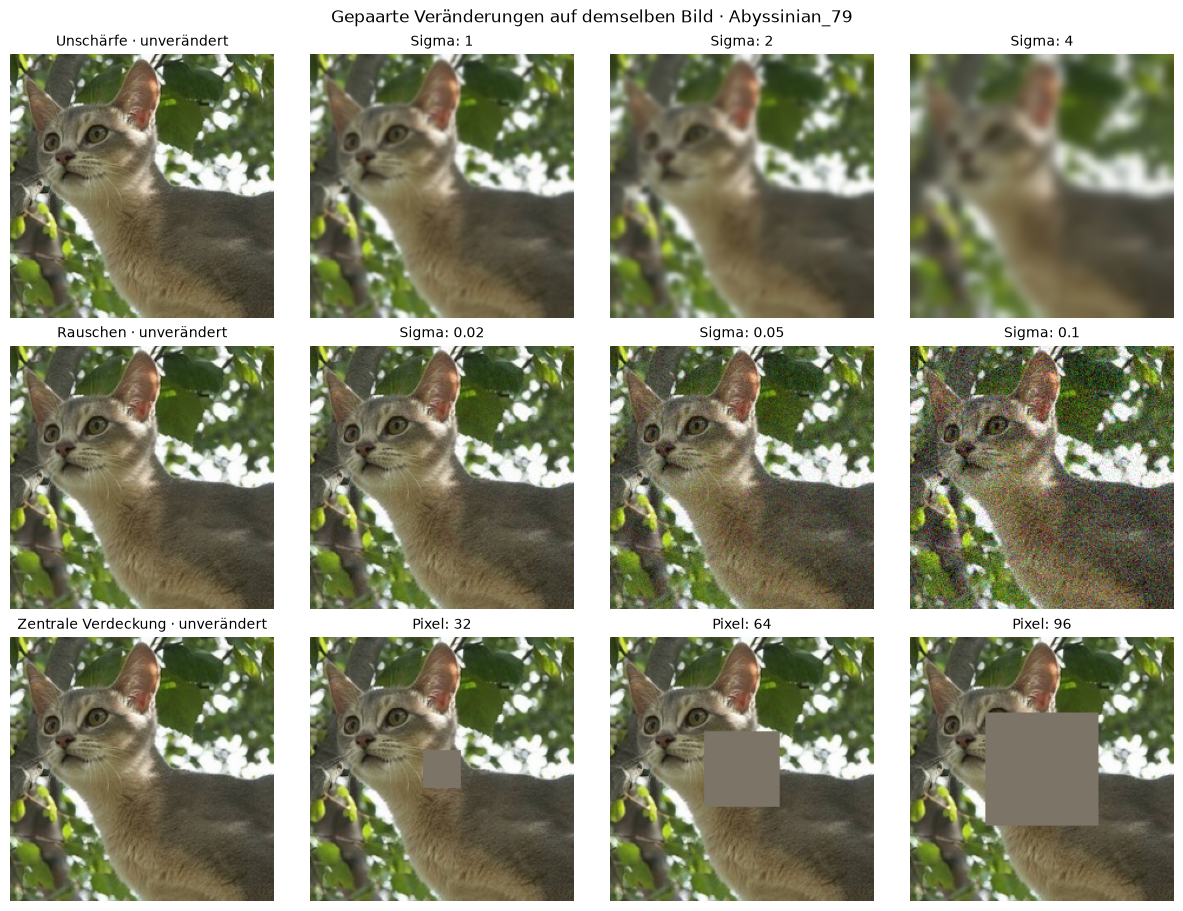

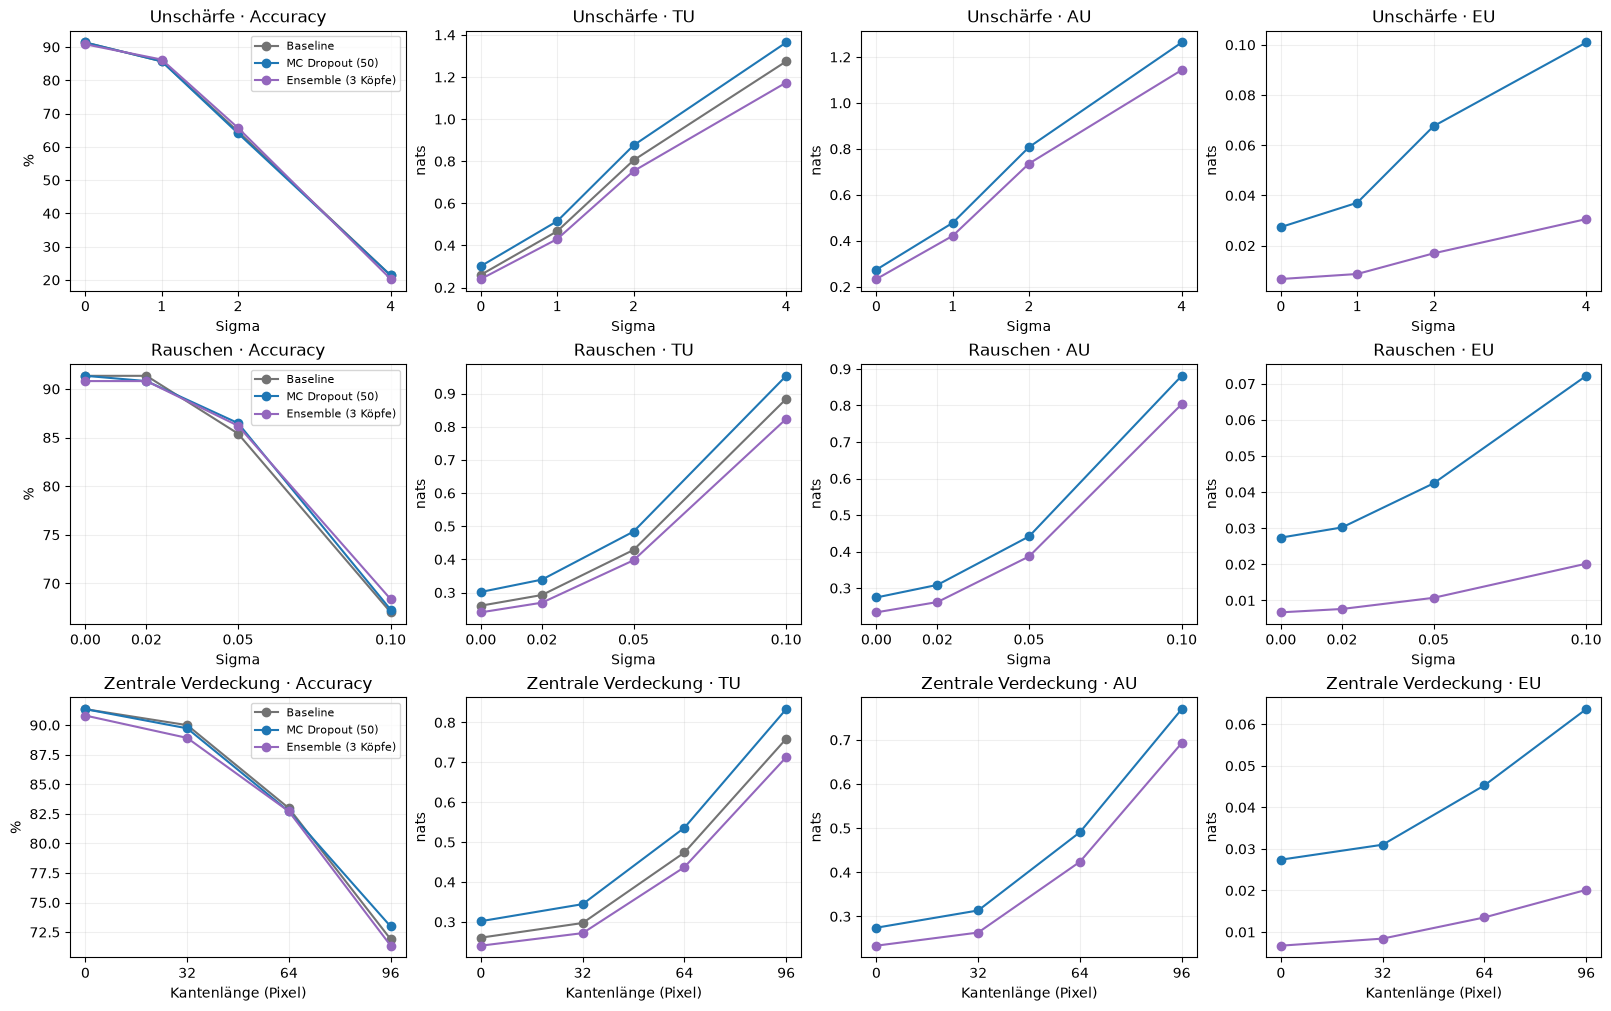

In [9]:
family_names = {"blur": "Unschärfe", "noise": "Rauschen", "occlusion": "Zentrale Verdeckung"}
example_id = corruption_ids[0]
example_crop = load_crop(example_id)
fig, axes = plt.subplots(3, 4, figsize=(12, 9), layout="constrained")
for row, family in enumerate(("blur", "noise", "occlusion")):
    axes[row, 0].imshow(example_crop)
    axes[row, 0].set_title(f"{family_names[family]} · unverändert", fontsize=10)
    for column, spec in enumerate([item for item in CORRUPTION_SPECS if item["family"] == family], start=1):
        with torch.random.fork_rng(devices=[]):
            torch.random.default_generator.manual_seed(SEED)
            image = corrupt_crop(example_crop, spec)
        axes[row, column].imshow(image.permute(1, 2, 0).clamp(0, 1).numpy())
        unit = "Pixel" if family == "occlusion" else "Sigma"
        axes[row, column].set_title(f"{unit}: {spec['value']:g}", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"Gepaarte Veränderungen auf demselben Bild · {example_id}")
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 10), layout="constrained")
plot_columns = [("accuracy", "Accuracy", "%"), ("mean_total", "TU", "nats"),
                ("mean_aleatoric", "AU", "nats"), ("mean_epistemic", "EU", "nats")]
for row, family in enumerate(("blur", "noise", "occlusion")):
    specs = [item for item in CORRUPTION_SPECS if item["family"] == family]
    xs = [0.0] + [spec["value"] for spec in specs]
    keys = ["clean"] + [spec["key"] for spec in specs]
    for column, (metric, title, unit) in enumerate(plot_columns):
        ax = axes[row, column]
        for method in METHODS:
            values = [corruption_metrics[key][method][metric] for key in keys]
            if any(value is None for value in values):
                continue
            scale = 100 if metric == "accuracy" else 1
            ax.plot(xs, np.array(values) * scale, marker="o", label=METHOD_NAMES[method],
                    color=METHOD_COLORS[method])
        ax.set_title(f"{family_names[family]} · {title}")
        ax.set_ylabel(unit)
        ax.set_xlabel("Kantenlänge (Pixel)" if family == "occlusion" else "Sigma")
        ax.set_xticks(xs)
        ax.grid(alpha=0.2)
        if column == 0:
            ax.legend(fontsize=8)
plt.show()

Die Kurven zeigen Mittelwerte über dieselben 370 Bilder, ohne behauptete
Populations-Konfidenzintervalle. Die Beispielansicht und die Metriken müssen gemeinsam
gelesen werden: Rauschen kann relevante Texturen zerstören, und eine zentrale Verdeckung
trifft nicht bei jedem Bild dasselbe Körperteil. Höhere EU oder AU ist hier eine beobachtete
Modellreaktion, keine automatisch bewiesene Ursache der Veränderung.

## 5. Weniger Trainingsbilder: Was können zusätzliche Daten verändern?

Für jede der drei Teilmengenziehungen (Seeds 10, 11, 12) verwenden wir
**verschachtelte Mengen mit 5 und 20 Bildern pro Rasse**. Alle Bilder der kleineren
Menge sind in der größeren enthalten. Die Modellseeds 0, 1, 2 bleiben gleich.
Der vollständige Trainingssplit und sein Ensemble werden einmal wiederverwendet.

Der Validierungssplit ändert sich nicht. Jedes Modell wird anschließend auf demselben
vollständigen Testsplit ausgewertet. Die Linien zeigen einzelne Teilmengenziehungen;
drei Ziehungen sind keine hinreichende Grundlage für präzise Aussagen über jede mögliche
Trainingsstichprobe. Auch bei wenig Pet-Trainingsdaten bringt VGG weiterhin ImageNet-Vorwissen mit.

| Bilder/Rasse | Teilmengenseed | Accuracy | NLL | mittlere AU | mittlere EU |
| :--- | ---: | ---: | ---: | ---: | ---: |
| 5 | 10 | 83.27% | 0.4962 | 0.5951 | 0.0091 |
| 5 | 11 | 83.32% | 0.4964 | 0.5903 | 0.0073 |
| 5 | 12 | 85.25% | 0.4446 | 0.5708 | 0.0075 |
| 20 | 10 | 89.21% | 0.3261 | 0.3446 | 0.0045 |
| 20 | 11 | 88.85% | 0.3512 | 0.4442 | 0.0062 |
| 20 | 12 | 89.02% | 0.3403 | 0.3643 | 0.0055 |
| alle (Ø 79.6) | — | 89.86% | 0.2825 | 0.2393 | 0.0071 |

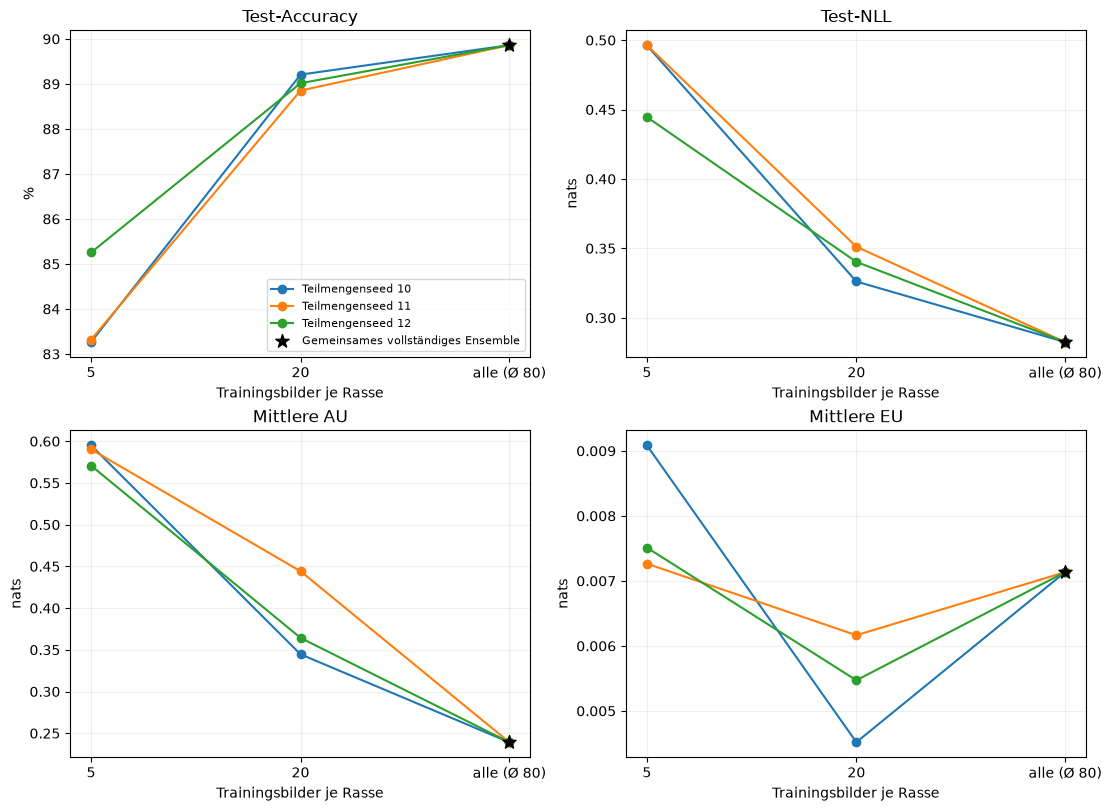

In [10]:
scarcity_metrics = {
    key: summarize(test_scores[key], test["labels"])
    for key in models["scarce"]
}
full_metrics = method_metrics["ensemble"]
full_per_breed = len(train_indices) / len(class_names)
scarcity_rows = ["| Bilder/Rasse | Teilmengenseed | Accuracy | NLL | mittlere AU | mittlere EU |",
                 "| :--- | ---: | ---: | ---: | ---: | ---: |"]
for key, record in models["scarce"].items():
    row = scarcity_metrics[key]
    scarcity_rows.append(
        f"| {record['per_breed']} | {record['subset_seed']} | {row['accuracy']:.2%} | "
        f"{row['nll']:.4f} | {row['mean_aleatoric']:.4f} | {row['mean_epistemic']:.4f} |"
    )
scarcity_rows.append(
    f"| alle (Ø {full_per_breed:.1f}) | — | {full_metrics['accuracy']:.2%} | "
    f"{full_metrics['nll']:.4f} | {full_metrics['mean_aleatoric']:.4f} | {full_metrics['mean_epistemic']:.4f} |"
)
display(Markdown("\n".join(scarcity_rows)))

fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
panels = [("accuracy", "Test-Accuracy", 100, "%"), ("nll", "Test-NLL", 1, "nats"),
          ("mean_aleatoric", "Mittlere AU", 1, "nats"), ("mean_epistemic", "Mittlere EU", 1, "nats")]
for ax, (metric, title, scale, unit) in zip(axes.flat, panels, strict=True):
    for seed in SUBSET_SEEDS:
        ys = [scarcity_metrics[f"k5_s{seed}"][metric], scarcity_metrics[f"k20_s{seed}"][metric],
              full_metrics[metric]]
        ax.plot([5, 20, full_per_breed], np.array(ys) * scale, marker="o", label=f"Teilmengenseed {seed}")
    ax.scatter([full_per_breed], [full_metrics[metric] * scale], color="black", marker="*", s=100,
               label="Gemeinsames vollständiges Ensemble", zorder=5)
    ax.set_xscale("log")
    ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xticks([5, 20, full_per_breed], ["5", "20", f"alle (Ø {full_per_breed:.0f})"])
    ax.set(title=title, xlabel="Trainingsbilder je Rasse", ylabel=unit)
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.show()

## 6. Ergebnisse festhalten und an die Erklärungsnotebooks übergeben

Die folgende Zusammenfassung wird aus den tatsächlich berechneten Ergebnissen erzeugt.
Sie benennt auch ausbleibende Verbesserungen. Kopfzustände, Testvorhersagen,
Unsicherheiten, Korruptionsmerkmale und Konfigurationen bleiben getrennt gespeichert.
Die Erklärungsnotebooks laden sie direkt und trainieren die Modelle nicht noch einmal.

In [11]:
findings = []
baseline_metrics = method_metrics["baseline"]
for method in ("mc_dropout", "ensemble"):
    row = method_metrics[method]
    change = 100 * (row["accuracy"] - baseline_metrics["accuracy"])
    nll_change = row["nll"] - baseline_metrics["nll"]
    findings.append(
        f"- **{METHOD_NAMES[method]}:** Accuracy-Änderung gegenüber der Baseline "
        f"{change:+.2f} Prozentpunkte; NLL-Änderung {nll_change:+.4f} "
        "(negativer NLL-Unterschied ist günstiger)."
    )
for method in ("mc_dropout", "ensemble"):
    candidates = [row for row in risk_rows if row["method"] == method]
    best = min(candidates, key=lambda row: row["aurc"])
    findings.append(
        f"- **Zurückstellen bei {METHOD_NAMES[method]}:** kleinste probly AURC unter den geprüften "
        f"Kriterien mit {CRITERION_NAMES[best['criterion']]} ({best['aurc']:.4f}); "
        "dies ist eine Beschreibung dieser Testauswertung, keine nachträglich optimierte Einsatzregel."
    )
for family in ("blur", "noise", "occlusion"):
    strongest = [spec for spec in CORRUPTION_SPECS if spec["family"] == family][-1]
    clean = corruption_metrics["clean"]["ensemble"]
    changed = corruption_metrics[strongest["key"]]["ensemble"]
    findings.append(
        f"- **{family_names[family]}, stärkste Stufe:** Ensemble-Accuracy "
        f"{clean['accuracy']:.1%} → {changed['accuracy']:.1%}; "
        f"mittlere EU {clean['mean_epistemic']:.4f} → {changed['mean_epistemic']:.4f} nats."
    )
small_accuracy = float(np.mean([scarcity_metrics[f"k5_s{seed}"]["accuracy"] for seed in SUBSET_SEEDS]))
small_eu = float(np.mean([scarcity_metrics[f"k5_s{seed}"]["mean_epistemic"] for seed in SUBSET_SEEDS]))
findings.append(
    f"- **5 Bilder/Rasse → vollständige Trainingsmenge:** mittlere Accuracy der drei "
    f"kleinen Ensembles {small_accuracy:.1%} → {full_metrics['accuracy']:.1%}; "
    f"mittlere EU {small_eu:.4f} → {full_metrics['mean_epistemic']:.4f} nats. "
    "Der Vergleich betrifft nur neue Köpfe im unveränderten VGG-Merkmalsraum."
)
medium_accuracy = float(np.mean([scarcity_metrics[f"k20_s{seed}"]["accuracy"] for seed in SUBSET_SEEDS]))
medium_eu = float(np.mean([scarcity_metrics[f"k20_s{seed}"]["mean_epistemic"] for seed in SUBSET_SEEDS]))
eu_rises_after20 = sum(
    full_metrics["mean_epistemic"] > scarcity_metrics[f"k20_s{seed}"]["mean_epistemic"]
    for seed in SUBSET_SEEDS
)
eu_decreases_monotonically = small_eu >= medium_eu >= full_metrics["mean_epistemic"]
eu_description = "EU im Datenvergleich" if eu_decreases_monotonically else "Nicht monotone EU"
findings.append(
    f"- **{eu_description}:** mittlere EU bei 5 / 20 / allen Bildern je Rasse: "
    f"{small_eu:.4f} / {medium_eu:.4f} / {full_metrics['mean_epistemic']:.4f} nats. "
    f"Nach dem Schritt 20 → alle liegt sie bei {eu_rises_after20} von {len(SUBSET_SEEDS)} "
    f"Teilmengenziehungen höher, während die mittlere Accuracy {medium_accuracy:.1%} → "
    f"{full_metrics['accuracy']:.1%} beträgt. Mehr Trainingsbilder garantieren für dieses "
    "kleine Kopfensemble keine monotone Abnahme der geschätzten epistemischen Unsicherheit."
)
display(Markdown("\n".join(findings)))

qa_summary = {
    "schema_version": 1,
    "baseline_fingerprint": baseline_fingerprint,
    "test_images": len(test["labels"]),
    "corruption_images": len(corruption_indices),
    "explanation_images": len(selection["explanation_indices"]),
    "model_metrics": method_metrics,
    "risk_coverage": risk_rows,
    "corruption_metrics": corruption_metrics,
    "scarcity_metrics": scarcity_metrics,
    "full_selected_epochs": models["full"]["best_epochs"],
    "findings": findings,
    "versions": versions(),
}
(PROBLY_DIR / "summary.json").write_text(json.dumps(qa_summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Modelle:", models_path)
print("Testauswertung:", predictions_path)
print("Gepaarte Veränderungen:", corruption_scores_path)
print("Maschinenlesbare Zusammenfassung:", PROBLY_DIR / "summary.json")

- **MC Dropout (50):** Accuracy-Änderung gegenüber der Baseline +0.08 Prozentpunkte; NLL-Änderung -0.0008 (negativer NLL-Unterschied ist günstiger).
- **Ensemble (3 Köpfe):** Accuracy-Änderung gegenüber der Baseline -0.25 Prozentpunkte; NLL-Änderung -0.0020 (negativer NLL-Unterschied ist günstiger).
- **Zurückstellen bei MC Dropout (50):** kleinste probly AURC unter den geprüften Kriterien mit 1 − max. Wahrscheinlichkeit (0.0144); dies ist eine Beschreibung dieser Testauswertung, keine nachträglich optimierte Einsatzregel.
- **Zurückstellen bei Ensemble (3 Köpfe):** kleinste probly AURC unter den geprüften Kriterien mit 1 − max. Wahrscheinlichkeit (0.0142); dies ist eine Beschreibung dieser Testauswertung, keine nachträglich optimierte Einsatzregel.
- **Unschärfe, stärkste Stufe:** Ensemble-Accuracy 90.8% → 20.3%; mittlere EU 0.0067 → 0.0306 nats.
- **Rauschen, stärkste Stufe:** Ensemble-Accuracy 90.8% → 68.4%; mittlere EU 0.0067 → 0.0202 nats.
- **Zentrale Verdeckung, stärkste Stufe:** Ensemble-Accuracy 90.8% → 71.4%; mittlere EU 0.0067 → 0.0201 nats.
- **5 Bilder/Rasse → vollständige Trainingsmenge:** mittlere Accuracy der drei kleinen Ensembles 83.9% → 89.9%; mittlere EU 0.0080 → 0.0071 nats. Der Vergleich betrifft nur neue Köpfe im unveränderten VGG-Merkmalsraum.
- **Nicht monotone EU:** mittlere EU bei 5 / 20 / allen Bildern je Rasse: 0.0080 / 0.0054 / 0.0071 nats. Nach dem Schritt 20 → alle liegt sie bei 3 von 3 Teilmengenziehungen höher, während die mittlere Accuracy 89.0% → 89.9% beträgt. Mehr Trainingsbilder garantieren für dieses kleine Kopfensemble keine monotone Abnahme der geschätzten epistemischen Unsicherheit.

Modelle: /Users/dschmid/Documents/Studium/LMU/Informatik mit integriertem Anwendungsfach (Statistik)/Module/Softwareentwicklungspraktikum - Trustworthy Machine Learning with Python/probly-gruppe-d/artifacts/oxford-pets-vgg16/probly/models.pt
Testauswertung: /Users/dschmid/Documents/Studium/LMU/Informatik mit integriertem Anwendungsfach (Statistik)/Module/Softwareentwicklungspraktikum - Trustworthy Machine Learning with Python/probly-gruppe-d/artifacts/oxford-pets-vgg16/probly/test_predictions.pt
Gepaarte Veränderungen: /Users/dschmid/Documents/Studium/LMU/Informatik mit integriertem Anwendungsfach (Statistik)/Module/Softwareentwicklungspraktikum - Trustworthy Machine Learning with Python/probly-gruppe-d/artifacts/oxford-pets-vgg16/probly/corruption_predictions.pt
Maschinenlesbare Zusammenfassung: /Users/dschmid/Documents/Studium/LMU/Informatik mit integriertem Anwendungsfach (Statistik)/Module/Softwareentwicklungspraktikum - Trustworthy Machine Learning with Python/probly-gruppe-d/arti

### Grenzen und Quellen

- Unterschiedliche AU/EU-Werte sind Schätzungen relativ zur Methode und zum gemeinsamen
  Merkmalssatz; die Bilddaten liefern keine direkten AU/EU-Zielwerte.
- Drei Köpfe bilden nur einen kleinen Ausschnitt möglicher Modelle ab. Gemeinsame
  VGG-Fehler und ImageNet-Vorwissen können Unterschiede verdecken.
- ECE ist ein binabhängiger Diagnosewert. Kalibrierung und Conformal Prediction sind
  hier bewusst noch kein eigener experimenteller Schritt.
- Testkurven und gezielte Diagnosefälle beschreiben diese Auswertung. Daraus abgeleitete
  Betriebsregeln müssten auf separaten Daten festgelegt und erneut geprüft werden.
- Das räumliche „Warum“ prüfen wir anschließend mit denselben Zuständen und Bildern in shapiq.

[probly: gemeinsame Pipeline](https://pwhofman.github.io/probly/latest/guide/core_pillars.html) ·
[probly: Methoden](https://pwhofman.github.io/probly/latest/guide/methods/second_order.html) ·
[probly: Unsicherheit auswerten](https://pwhofman.github.io/probly/latest/guide/uncertainty/evaluating.html) ·
[torchvision 0.25: GaussianNoise](https://docs.pytorch.org/vision/0.25/generated/torchvision.transforms.v2.GaussianNoise.html)

Die konkreten Aufrufe wurden zusätzlich gegen den lokalen probly-Checkout geprüft.